# Monotonicity constraints and the causal estimate

A monotonicity constraint supplies direction information: the analyst tells the
model that raising an exposure can only raise (or only lower) the response, on
grounds that come from biology or mechanism, not from the data. A shape
constraint could move the fitted curve toward the causal effect and change
which variables are selected. This study measures both outcomes. The
constraint improves the exposure-effect estimate only when a confounder is
missing from the model, and it does not change the selected variables.

This case teaches how a shape constraint changes a causal estimate under declared
adjustment sets. The known effect provides a reference for both the fitted curve and the
variables selected along the path.


:::{admonition} What this study estimates
:class: dropdown

| | |
|---|---|
| **Target** | when a monotonicity constraint moves the estimate toward the causal effect and when it does not |
| **Observed response** | a simulated outcome |
| **Estimand** | the causal dose–response function defined by the simulation |
| **Units** | simulated, arbitrary scale |
| **Sampling unit** | one simulated observation |
| **Dependence** | independent given the simulated confounder |
| **Split / resampling unit** | the observation |
| **Tuning** | `mstop` by cross-validated risk |
| **Uncertainty** | repeated simulation |
| **Claim type** | causal within the simulation, which is what lets the constraint's effect on bias be measured at all |
:::


## The data

The data are simulated, so the causal effect is known. Three hundred patients
each receive an exposure $E$ between 0 and 10 and record a response $y$. A
confounder $U$ (severity of illness) raises the exposure a patient receives
and lowers the response, so high-$E$ patients are sicker to begin with. That
is confounding by indication {cite}`walker1996confounding`.

$$
\begin{aligned}
U &\sim N(0, 1) \\
E &= \operatorname{clip}(5 + 1.5\,U + \varepsilon_E,\ 0, 10),
  \qquad \varepsilon_E \sim N(0, 1.2^2) \\
y &= 3\log(1 + E) - 2.5\,U + \varepsilon_y,
  \qquad \varepsilon_y \sim N(0, 1)
\end{aligned}
$$

The causal effect of $E$, with $U$ held fixed, is $3\log(1+E)$, which rises
at every dose. The $-2.5\,U$ term is what makes the marginal $E$-$y$ relation
bend downward at high $E$: high-$E$ patients are also high-$U$, and $U$
lowers the response whether or not the drug works.


In [1]:
import warnings

import numpy as np
import polars as pl

import mboostrs as mb

n_obs = 300


def generate(rng, rows=n_obs, confounded=True, gamma=2.5):
    # gamma is how hard U pushes the response down; it sets the strength of
    # the confounding. gamma = 0 leaves U raising E but not affecting y.
    U = rng.normal(0, 1, rows)
    E = (np.clip(5 + 1.5 * U + rng.normal(0, 1.2, rows), 0, 10)
         if confounded else rng.uniform(0, 10, rows))
    y = 3 * np.log1p(E) - gamma * U + rng.normal(0, 1, rows)
    return {"E": E, "U": U, "y": y}


rng = np.random.default_rng(2026)
data = generate(rng)
grid_E = np.linspace(0, 10, 60)
causal_curve = 3 * np.log1p(grid_E)
causal_curve = causal_curve - causal_curve.mean()

print(f"n = {n_obs}")
print(f"corr(E, U) {np.corrcoef(data['E'], data['U'])[0, 1]:.3f}")
print(f"corr(E, y) {np.corrcoef(data['E'], data['y'])[0, 1]:.3f}"
      f"   (the causal effect is positive at every dose)")


n = 300
corr(E, U) 0.790
corr(E, y) -0.456   (the causal effect is positive at every dose)


In the sample, exposure and response correlate negatively, while the drug
raises the response at every dose. The negative sign is $U$'s doing: $U$
pushes the exposure up and the response down.


## Fits with and without the confounder

Two adjustment sets are compared. In the first, $U$ is in the model — the
right confounder is measured. In the second, $U$ is unavailable and the
candidates are only $E$ and the noise. Each adjustment set is fitted twice on
$E$: once with `bbs(E, df=4)`, a P-spline free to take any shape, and once
with `bmono(E, df=4, constraint='increasing')`, the same spline forbidden to
fall {cite}`hofner2011monotonicity`. The constraint is logical — more of a
beneficial exposure does not lower the response — and it comes from
mechanism, not from the data.

The monotone fit uses the exact quadratic-programming solver (`type=
'quad.prog'`, the default), which solves each boosting step exactly so the
constraint holds at every iteration.


## Distance from the causal effect

The quantity of interest is the fitted partial effect of $E$, with every other
predictor held at its mean, centred to average zero so it is comparable with
the centred causal curve. The table records the average distance of that
curve from the causal effect across the dose grid, the number of dose-grid
intervals on which the fit falls, and the cross-validated stopping iteration
(mstop) for each combination of adjustment set and dose learner.


In [2]:
adjustments = {"U in the model": " + bbs(U, df=4)", "U missing": ""}
dose_terms = {
    "free": "bbs(E, df=4)",
    "monotone": "bmono(E, df=4, constraint='increasing', type='quad.prog')",
}
folds = mb.cv_weights(n_obs, type="kfold", B=10, seed=1)
fits, rows = {}, []
# Reuse the declared folds so comparisons differ by model, not by split.

def partial_effect(model, source, with_U):
    grid = {"E": grid_E}
    if with_U:
        grid["U"] = np.full(len(grid_E), float(np.mean(source["U"])))
    fitted = np.asarray(model.predict(newdata=grid)).ravel()
    return fitted - fitted.mean()


for adjustment, extra in adjustments.items():
    with_U = adjustment == "U in the model"
    for shape, dose_term in dose_terms.items():
        model = mb.gamboost(f"y ~ {dose_term}{extra}", data=data,
                            family=mb.Gaussian(), control=mb.boost_control(400, 0.1))
        result = model.cvrisk(folds=folds)
        stopped = model[:result.optimal_mstop]
        fits[(adjustment, shape)] = stopped
        curve = partial_effect(stopped, data, with_U)
        rows.append({
            "adjustment": adjustment,
            "dose learner": shape,
            "mstop": result.optimal_mstop,
            "distance from the causal effect": round(float(np.mean(np.abs(curve - causal_curve))), 3),
            "falling intervals": int((np.diff(curve) < -1e-6).sum()),
        })

display(pl.DataFrame(rows))


/Users/fcela/src/public_github/mboostrs/python/mboostrs/gamboost.py:3082: UserWarning: optimal mstop 400 is within 5% of the search cap 400; the search range was exhausted — consider increasing mstop and re-running cvrisk.
  result = CvRiskResult(
/tmp/ipykernel_67541/244696811.py:23: RuntimeWarning: the cross-validated risk is still falling at mstop=400, the largest iteration evaluated, so the reported optimal_mstop=400 is where the path stopped rather than where the risk turns. Refit with a larger mstop and cross-validate again on the same folds: `model.continue_to(800)` then `cvrisk(folds=...)`. (`continue_to` resumes the retained gradient where the fit kept one, and otherwise costs a full path; `parity_notes(include_global=True)` says which routes resume.)
  result = model.cvrisk(folds=folds)
/Users/fcela/src/public_github/mboostrs/python/mboostrs/gamboost.py:3082: UserWarning: optimal mstop 399 is within 5% of the search cap 400; the search range was exhausted — consider increasin

adjustment,dose learner,mstop,distance from the causal effect,falling intervals
str,str,i64,f64,i64
"""U in the model""","""free""",400,0.237,0
"""U in the model""","""monotone""",399,0.195,0
"""U missing""","""free""",31,2.683,45
"""U missing""","""monotone""",1,1.543,0


With $U$ **in the model**, the constraint barely moves the estimate. The free
fit is already close to the causal effect and already monotone — zero falling
intervals in this sample — so forbidding it to fall removes almost nothing;
the distance moves from 0.24 to 0.20, a small change that averages to about
0.01 across twenty samples and is inside the run-to-run variation. With $U$
**missing**, the constraint matters: the free fit, chasing the downward bend
that $U$ puts into the marginal $E$-$y$ relation, falls across most of the
dose range and ends far from the causal curve; the monotone fit is forbidden
to take that bend, so it stays closer to the truth, and boosting stops early
because the shape it is allowed to fit has little left to add.


The chart shows the four fitted partial-effect curves against the causal
effect. The two top panels put $U$ in the model — there the free and
constrained curves are nearly on top of each other and on the truth. The two
bottom panels leave $U$ out — there the free fit bends down where $U$ pulls
the response, and the constrained fit, unable to follow, sits between the
free fit and the causal curve.


In [3]:
import altair as alt
# Compute the table or diagnostic interpreted in the following paragraph.
frames = []

for adjustment in adjustments:
    with_U = adjustment == "U in the model"
    for shape in dose_terms:
        curve = partial_effect(fits[(adjustment, shape)], data, with_U)
        frames.append(pl.DataFrame({
            "E": grid_E,
            "response": curve,
            "curve": ["free fit" if shape == "free" else "monotone fit"] * len(grid_E),
            "panel": [adjustment] * len(grid_E),
        }))
    frames.append(pl.DataFrame({
        "E": grid_E, "response": causal_curve,
        "curve": ["causal effect"] * len(grid_E),
        "panel": [adjustment] * len(grid_E),
    }))

curves = pl.concat(frames)

colour = alt.Color(
    "curve:N", title=None,
    scale=alt.Scale(domain=["causal effect", "free fit", "monotone fit"],
                    range=["#bbbbbb", "#e15759", "#4e79a7"]),
)


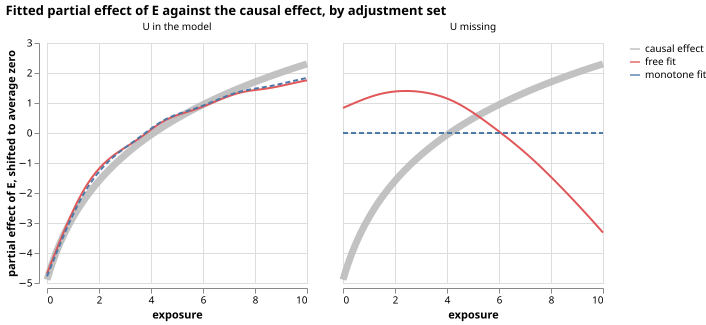

In [4]:
truth = alt.Chart(curves).transform_filter(
    alt.datum.curve == "causal effect"
).mark_line(strokeWidth=7, opacity=0.9).encode(
    x=alt.X("E:Q", title="exposure"),
    y=alt.Y("response:Q", title="partial effect of E, shifted to average zero"),
    color=colour,
)

fitted = alt.Chart(curves).transform_filter(
    alt.datum.curve != "causal effect"
).mark_line(strokeWidth=2).encode(
    x=alt.X("E:Q"),
    y=alt.Y("response:Q"),
    color=colour,
    strokeDash=alt.condition(alt.datum.curve == "monotone fit",
                             alt.value([5, 3]), alt.value([1, 0])),
)

alt.layer(truth, fitted).properties(width=260, height=240).facet(
    column=alt.Column("panel:N", title=None,
                      sort=["U in the model", "U missing"]),
).properties(title="Fitted partial effect of E against the causal effect, by adjustment set")


## Constraint with the confounder adjusted

The constraint forbids a shape the free fit does not want. With $U$ held
fixed in the model, the marginal $E$-$y$ bend that $U$ creates is absorbed by
the $U$ term, and what is left for $E$ is the true monotone effect. The free
spline, fitted to that residual, is already monotone. The constraint removes
the occasional wiggle across the dose grid and nothing else — the distance to
the causal effect does not move.

A constraint changes the exposure learner's fitted coefficients and hence
the residuals available to every other learner. In this adjusted simulation,
the $U$ term already models the severity contribution and the free exposure
curve is nearly monotone. The constraint therefore changes little in either
the exposure estimate or subsequent learner choices.


## Variable selection with and without the constraint

The selection of $U$ is set by $U$'s own predictive contribution to the
response, which the constraint on $E$ does not touch. The table records how
many of the cross-validated boosting steps each fit spent on the $E$ learner
and on the $U$ learner, in the regime where $U$ is a candidate.


In [5]:
import collections

selection_rows = []
for adjustment, extra in adjustments.items():
    if adjustment != "U in the model":
        continue
    for shape, dose_term in dose_terms.items():
        model = mb.gamboost(f"y ~ {dose_term}{extra}", data=data,
                            family=mb.Gaussian(), control=mb.boost_control(400, 0.1))
        result = model.cvrisk(folds=folds)
        ms = result.optimal_mstop
        steps = collections.Counter(list(model.selected)[:ms])
        selection_rows.append({
            "dose learner": shape,
            "mstop": ms,
            "steps on E": steps.get("E", 0),
            "steps on U": steps.get("U", 0),
        })
display(pl.DataFrame(selection_rows))


/tmp/ipykernel_67541/3156002393.py:10: RuntimeWarning: the cross-validated risk is still falling at mstop=400, the largest iteration evaluated, so the reported optimal_mstop=400 is where the path stopped rather than where the risk turns. Refit with a larger mstop and cross-validate again on the same folds: `model.continue_to(800)` then `cvrisk(folds=...)`. (`continue_to` resumes the retained gradient where the fit kept one, and otherwise costs a full path; `parity_notes(include_global=True)` says which routes resume.)
  result = model.cvrisk(folds=folds)


dose learner,mstop,steps on E,steps on U
str,i64,i64,i64
"""free""",400,256,144
"""monotone""",399,232,167


With $U$ in the model, both fits select both variables, and the constraint
leaves the set unchanged: $E$ stays in the model and so does $U$. What it
shifts is the *balance* of the iterations, slightly toward $U$ — in this
sample the free fit spends 256 steps on $E$ and 144 on $U$, the constrained
fit 232 on $E$ and 167 on $U$; averaged over twenty samples, 168/155 free
against 160/163 constrained. The shift is in the expected direction: the
constrained $E$ absorbs less of the residual, so a little more of it falls
to $U$.

In this simulation, the shape constraint does not change the selected set. The set of selected variables is the same; only
the iteration split shifts, and only slightly. Selection is driven by a
predictor's own contribution to the response, which the constraint on another
learner does not alter except in the narrow case where the other predictor
was specifically compensating for the forbidden shape. With the confounder in
the model that case does not arise.


## Results over twenty data sets

The single sample above is one draw. Averaged over twenty fresh data sets,
the pattern is the same.


In [6]:
def one_run(rng):
    d = generate(rng)
    out = {}
    for adjustment, extra in adjustments.items():
        with_U = adjustment == "U in the model"
        for shape, dose_term in dose_terms.items():
            model = mb.gamboost(f"y ~ {dose_term}{extra}", data=d,
                                family=mb.Gaussian(),
                                control=mb.boost_control(400, 0.1))
            result = model.cvrisk(folds=mb.cv_weights(n_obs, type="kfold", B=10,
                                                     seed=1))
            ms = result.optimal_mstop
            curve = partial_effect(model[:ms], d, with_U)
            steps = collections.Counter(list(model.selected)[:ms])
            out[(adjustment, shape)] = {
                "distance": float(np.mean(np.abs(curve - causal_curve))),
                "falling": int((np.diff(curve) < -1e-6).sum()),
                "mstop": float(ms),
                "steps on E": float(steps.get("E", 0)),
                "steps on U": float(steps.get("U", 0)),
            }
    return out
# Reuse the declared folds so comparisons differ by model, not by split.
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    acc = {}
    for seed in range(1, 21):
        for k, v in one_run(np.random.default_rng(seed)).items():
            acc.setdefault(k, []).append(v)

summary_rows = []


In [7]:
for adjustment in adjustments:
    for shape in dose_terms:
        vs = acc[(adjustment, shape)]
        summary_rows.append({
            "adjustment": adjustment,
            "dose learner": shape,
            "distance": round(float(np.mean([v["distance"] for v in vs])), 3),
            "falling intervals": round(float(np.mean([v["falling"] for v in vs])), 1),
            "mstop": round(float(np.mean([v["mstop"] for v in vs])), 0),
            "steps on E": round(float(np.mean([v["steps on E"] for v in vs])), 0),
            "steps on U": round(float(np.mean([v["steps on U"] for v in vs])), 0),
        })

display(pl.DataFrame(summary_rows))


adjustment,dose learner,distance,falling intervals,mstop,steps on E,steps on U
str,str,f64,f64,f64,f64,f64
"""U in the model""","""free""",0.184,1.6,322.0,168.0,155.0
"""U in the model""","""monotone""",0.176,0.0,324.0,160.0,163.0
"""U missing""","""free""",2.547,51.3,65.0,65.0,0.0
"""U missing""","""monotone""",1.542,0.0,21.0,21.0,0.0


With $U$ in the model, the constraint changes the distance to the causal
effect by an amount that is inside the run-to-run variation, and it changes
neither the number of steps spent on $E$ nor the number spent on $U$. With
$U$ missing, the constraint closes about 40 percent of the distance between
the free fit and the causal effect, removes the downward bend entirely, and
collapses the stopping iteration — boosting stops early because the shape it
is allowed to fit has little left to add.

The repeated fits show that the constraint reduces one component of the bias
when the omitted confounder makes the free dose curve decrease. The remaining
distance to the causal curve shows why direction knowledge cannot replace
adjustment for that confounder.


## Findings

The study supports three claims. With $U$ in the model, the constraint does
not move the estimate of $E$'s effect, because the free fit is already
monotone. With $U$ missing, the constraint pulls the estimate of $E$'s effect
materially closer to the causal curve, by forbidding the bend that the
unmeasured confounder puts into the marginal $E$-$y$ relation. And in neither
regime does the constraint change which variables the model selects —
selection of $U$ is the same under both fits.

It does not support the stronger claim that out-of-band information about an
effect's shape steers variable selection toward the true predictors. The
constraint acts on the estimate, not on the set of selected variables, and it
acts on the estimate only when the missing confounder bends the free fit
against the known direction.


## Conclusions

A shape constraint carries information the data do not: that raising an
exposure can only raise the response. That information helps the estimate of
the exposure effect only in the regime where a confounder is missing from the
model and bends the free fit against the truth. With the confounder in the
model the free fit is already monotone, and the constraint has nothing to
add.

The constraint does not change which variables the model selects. Selection
of the confounder is set by its own contribution to the
response and is the same whether the dose learner is free or constrained. The
constraint is a proxy for the confounder's effect on the shape of one
coefficient, not a substitute for including the confounder in the adjustment
set {cite}`pearl2009causality`.

Two limitations apply. The constraint affects the estimate only where the
bias violates its direction; confounding
that bends the curve the other way, or shifts it without changing its shape,
is invisible to it. And the comparison rests on the simulated setting: one
confounder, a Gaussian response, an additive model, and a constraint known
in advance to be true — where the direction itself is in doubt, a bend in the
constrained fit has two explanations and this comparison does not separate
them.


```{bibliography}
:filter: docname in docnames
```